In [1]:
from pathlib import Path

PROJECT = Path(r"C:\Users\LX\Desktop\quebec")
OUTPUT_ROOT = PROJECT / "L_revision"

# Use the prepared network and demand inputs.
INPUT_MANIFEST = (PROJECT / "revision/fixed_10m_routing_release/07_exact_routing_inputs"
                  / "runs/20260926T235556_632053Z/manifest.json")
ROUTING_SUCCESS_POINTER = (OUTPUT_ROOT / "exact_pareto_routing"
                           / "LATEST_FULL_SUCCESS.json")

MAIN_DETOUR_PERCENT = 20
EXPECTED_SAMPLES = 2500
PROGRESS_EVERY = 1000
SHOW_FIGURES = False

CODE_FINGERPRINT = '47e32e408a7a8db17323a4c95081fc7513128c85bbc1377a7082347ad09ea483'

In [2]:
import importlib.util

required_packages = ("numpy", "pandas", "matplotlib")
missing_packages = [name for name in required_packages if importlib.util.find_spec(name) is None]
if missing_packages:
    raise ImportError("Install missing packages: %pip install " + " ".join(missing_packages))

from datetime import datetime, timezone
from bisect import bisect_right
from fractions import Fraction
import gc
import gzip
import hashlib
import json
import math
import platform
import sys
import time
import traceback

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

VERSION = "rq2_detour_tradeoffs_v4"
BUDGET_PERCENTAGES = (5, 10, 15, 20)
DISTANCE_LABELS = ("0–<0.5 km", "0.5–<1 km", "1–<2 km", "2–<5 km", "≥5 km")

In [3]:
def require(condition, message):
    if not condition:
        raise RuntimeError(message)


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def load_json(path):
    opener = gzip.open if str(path).endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8") as stream:
        return json.load(stream)


def replace_file(temporary, destination):
    for attempt in range(5):
        try:
            temporary.replace(destination)
            return
        except PermissionError:
            if attempt == 4:
                raise
            time.sleep(0.5 * (attempt + 1))


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("w", encoding="utf-8", newline="\n") as stream:
        json.dump(value, stream, ensure_ascii=False, indent=2, allow_nan=False)
    replace_file(temporary, path)


def read_csv(path):
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")


def atomic_csv(path, value):
    path = Path(path)
    temporary = path.with_name(path.name + ".tmp")
    pd.DataFrame(value).to_csv(temporary, index=False, encoding="utf-8-sig", lineterminator="\n")
    replace_file(temporary, path)


def load_sources(input_manifest, routing_success_pointer, expected_samples):
    source07_path, pointer_path = Path(input_manifest), Path(routing_success_pointer)
    require(pointer_path.is_file(), f"Full-routing success pointer not found: {pointer_path}")
    pointer_bytes = pointer_path.read_bytes()
    pointer = json.loads(pointer_bytes)
    manifest_path = pointer_path.parent / "runs" / pointer["run_id"] / "manifest.json"
    require(manifest_path.is_file(), f"Routing manifest not found: {manifest_path}")
    require(source07_path.is_file(), f"Input manifest not found: {source07_path}")
    routing_hash = file_sha256(manifest_path)
    require(routing_hash == pointer["manifest_sha256"], "Routing success pointer/manifest hash mismatch")
    manifest = load_json(manifest_path)
    require(pointer["run_id"] == manifest_path.parent.name == manifest["run_id"], "Routing run ID mismatch")
    require(manifest["mode"] == "full" and manifest["status"] == "completed_full"
            and manifest["all_2500_samples_all_hours_complete"] is True
            and manifest["incomplete_or_not_run"] == 0, "Routing run is not complete")
    require(manifest["frontier_detour_percent"] == 20
            and manifest["minimum_exposure_baseline_has_distance_cap"] is False,
            "Unexpected frontier scope or minimum-exposure baseline")
    require(file_sha256(source07_path) == manifest["input_manifest_sha256"], "Routing/input manifest hash mismatch")
    source07 = load_json(source07_path)
    require(source07["status"] == "completed", "Input preparation is incomplete")
    require(source07.get("model_version") == "fixed10m_min_EDGE_ID_common_distance_v1", "Unexpected input model")
    directory07, directory08 = source07_path.parent, manifest_path.parent
    hashes07 = {item["file"]: item["sha256"] for item in source07["output_files"]}
    used = [dict(file=str(pointer_path), sha256=hashlib.sha256(pointer_bytes).hexdigest()),
            dict(file=str(manifest_path), sha256=routing_hash),
            dict(file=str(source07_path), sha256=manifest["input_manifest_sha256"])]
    for name in ("routing_arrays.npz", "arcs.csv.gz", "od_samples.csv", "unique_od_tasks.csv"):
        path = directory07 / name
        observed = file_sha256(path)
        require(observed == hashes07[name], f"Input file hash mismatch: {name}")
        used.append(dict(file=str(path), sha256=observed))
    with np.load(directory07 / "routing_arrays.npz", allow_pickle=False) as data:
        arrays = dict(u=data["u"].tolist(), v=data["v"].tolist(),
            distance=[int(x) for x in data["distance_exact_integer"]],
            distance_places=int(data["distance_decimal_places"]), hours=list(map(int, data["hours"])))
        arrays["exposure"] = {hour: [int(x) for x in data["exposure_exact_integer"][i]]
                              for i, hour in enumerate(arrays["hours"])}
        arrays["exposure_places"] = dict(zip(arrays["hours"], map(int, data["exposure_decimal_places"])))
    arcs = read_csv(directory07 / "arcs.csv.gz")
    samples = read_csv(directory07 / "od_samples.csv")
    tasks = read_csv(directory07 / "unique_od_tasks.csv")
    for frame in (samples, tasks):
        for column in ("od_task_index", "origin_node_index", "destination_node_index"):
            frame[column] = frame[column].map(int)
    samples["sample_sequence"] = samples["sample_sequence"].map(int)
    tasks["sample_multiplicity"] = tasks["sample_multiplicity"].map(int)
    require(samples.sample_id.is_unique and len(samples) == expected_samples, "Incorrect sample count or duplicate sample IDs")
    require(sorted(samples.sample_sequence) == list(range(1, expected_samples + 1)), "Incomplete sample sequence")
    require(tasks.od_task_index.is_unique, "Duplicate OD task IDs")
    multiplicities = samples.od_task_index.value_counts().to_dict()
    require(multiplicities == dict(zip(tasks.od_task_index, tasks.sample_multiplicity)), "Sample multiplicity mismatch")
    for task in tasks.itertuples(index=False):
        sub = samples.loc[samples.od_task_index == task.od_task_index]
        for col in ("origin_node_index", "destination_node_index", "origin_route_node", "destination_route_node"):
            require(sub[col].eq(getattr(task, col)).all(), f"Sample/task mismatch: {col}")
    require(arcs.arc_index.map(int).tolist() == list(range(len(arrays["u"]))), "Incorrect arc-index order")
    require(arcs.u_index.map(int).tolist() == arrays["u"] and arcs.v_index.map(int).tolist() == arrays["v"], "Arc endpoint mismatch")
    require(arcs.distance_exact_integer.map(int).tolist() == arrays["distance"], "Arc distance mismatch")
    require(all(d > 0 for d in arrays["distance"]) and
            all(c >= 0 for values in arrays["exposure"].values() for c in values), "Distances must be positive and exposures nonnegative")
    hours = arrays["hours"]
    require(hours == [11, 12, 13, 14, 15] == source07["hours"], "Unexpected hours")
    keys = [(int(t), h) for t in tasks.od_task_index for h in hours]
    require(manifest["completed_tasks"] == manifest["requested_tasks"] == source07["solve_tasks"] == len(keys), "Routing task-count mismatch")
    require(manifest["sample_hour_rows"] == expected_samples * len(hours), "Routing sample-hour count mismatch")
    index_path = directory08 / "task_file_index.json"
    index = load_json(index_path)
    used.append(dict(file=str(index_path), sha256=file_sha256(index_path)))
    # Accept task indexes written on either Windows or POSIX systems.
    task_hashes = {str(item["file"]).replace("\\", "/"): item["sha256"] for item in index}
    wanted = {f"tasks/od_{t:05d}_hour_{h}.json.gz" for t, h in keys}
    require(len(index) == len(task_hashes) and set(task_hashes) == wanted, "Missing, duplicate or unexpected task files")
    return dict(manifest=manifest, arrays=arrays, samples=samples, tasks=tasks, keys=keys,
                directory08=directory08, task_hashes=task_hashes, used=used,
                source08_manifest_sha256=routing_hash)

In [4]:
def verify_route(route, source, target, arrays, exposure):
    node, distance, cost = source, 0, 0
    visited = {node}
    for edge in route:
        require(type(edge) is int and 0 <= edge < len(arrays["u"]), "Invalid route arc index")
        require(arrays["u"][edge] == node, "Discontinuous route")
        node = arrays["v"][edge]
        require(node not in visited, "Cycle in a saved efficient route")
        visited.add(node)
        distance += arrays["distance"][edge]
        cost += exposure[edge]
    require(node == target, "Incorrect route destination")
    return distance, cost


def verify_dag(result, arrays, exposure):
    dag = result["dag"]
    nodes, predecessors = dag["node"], dag["predecessors"]
    ds = [int(x) for x in dag["distance_integer"]]
    cs = [int(x) for x in dag["exposure_integer"]]
    n, links, counts = len(nodes), 0, [1] + [0] * (len(nodes) - 1)
    require(n > 0 and n == len(ds) == len(cs) == len(predecessors), "DAG array-length mismatch")
    require(dag["root"] == 0 and nodes[0] == result["origin_node_index"]
           and ds[0] == cs[0] == 0 and predecessors[0] == [], "Invalid DAG root label")
    for label in range(1, n):
        incoming = predecessors[label]
        require(bool(incoming), "Unreachable DAG label")
        unique = set()
        for previous, edge in incoming:
            require(type(previous) is int and type(edge) is int and 0 <= previous < label
                   and 0 <= edge < len(arrays["u"]), "Invalid DAG predecessor or arc index")
            require((previous, edge) not in unique, "Duplicate DAG predecessor link")
            unique.add((previous, edge))
            require(nodes[previous] == arrays["u"][edge] and nodes[label] == arrays["v"][edge], "DAG endpoint mismatch")
            require(ds[previous] + arrays["distance"][edge] == ds[label]
                   and cs[previous] + exposure[edge] == cs[label], "DAG integer costs do not conserve")
            counts[label] = min(2, counts[label] + counts[previous])
            links += 1
    terminals = dag["terminals"]
    require(bool(terminals) and len(set(terminals)) == len(terminals), "Missing or duplicate terminal labels")
    require(all(type(t) is int and 0 <= t < n and nodes[t] == result["destination_node_index"]
               for t in terminals), "Incorrect DAG terminal nodes")
    points = [(ds[t], cs[t]) for t in terminals]
    require(all(points[i][0] < points[i + 1][0] and points[i][1] > points[i + 1][1]
               for i in range(len(points) - 1)), "Duplicate, dominated or unsorted objective points")
    route_count = min(2, sum(counts[t] for t in terminals))
    require(route_count == result["route_count_capped_at_two"]
           and result["multiple_routes"] == (route_count > 1), "Route-multiplicity classification mismatch")
    require(result["stats"]["dag_labels"] == n and result["stats"]["dag_links"] == links
           and result["stats"]["frontier_points"] == len(points), "DAG statistics mismatch")
    return points, terminals, links


def verify_route_in_dag(route, terminal, dag):
    current = terminal
    for edge in reversed(route):
        previous = [p for p, e in dag["predecessors"][current] if e == edge]
        require(len(previous) == 1, "Representative route cannot be recovered from its terminal")
        current = previous[0]
    require(current == dag["root"], "Representative route does not reach the root label")


def distance_band(distance, places):
    scale = 10**places
    return bisect_right([500 * scale, 1000 * scale, 2000 * scale, 5000 * scale], distance)


def route_metrics(d0, c0, d, c, dmin, cmin, distance_places, exposure_places):
    require(d0 > 0 and d >= d0 and 0 <= cmin <= c <= c0, "Invalid baseline or budget cost ordering")
    gain, extra = c0 - c, d - d0
    require(gain == 0 or extra > 0, "Positive exposure reduction requires a strictly longer route")
    return dict(distance_integer=str(d), exposure_integer=str(c),
        distance_m=d / 10**distance_places, exposure_cost_w_per_m=c / 10**exposure_places,
        additional_distance_m=extra / 10**distance_places, achieved_detour_pct=100 * extra / d0,
        exposure_reduction_integer=str(gain), exposure_reduction_cost_w_per_m=gain / 10**exposure_places,
        exposure_reduction_pct=100 * gain / c0 if c0 else np.nan,
        relative_reduction_defined=c0 > 0, positive_reduction=gain > 0,
        reduction_at_least_1pct=(c0 > 0 and 100 * gain >= c0),
        reduction_at_least_5pct=(c0 > 0 and 100 * gain >= 5 * c0),
        reduction_at_least_10pct=(c0 > 0 and 100 * gain >= 10 * c0),
        reaches_unbounded_minimum_exposure=c == cmin,
        achievable_gain_captured_pct=100 * gain / (c0 - cmin) if c0 > cmin else np.nan)


def analyze_task(result, task, hour, sources):
    arrays, manifest = sources["arrays"], sources["manifest"]
    require(result["status"] == "completed" and result["complete_frontier_within_20pct"] is True, "Incomplete routing task")
    require(result["od_task_index"] == task.od_task_index and result["hour"] == hour, "Task ID or hour mismatch")
    require(result["origin_node_index"] == task.origin_node_index and
           result["destination_node_index"] == task.destination_node_index, "Task OD endpoints mismatch")
    require(result["solver_fingerprint"] == manifest["solver_fingerprint"] and
           result["input_manifest_sha256"] == manifest["input_manifest_sha256"], "Task solver or input provenance mismatch")
    dp, cp = arrays["distance_places"], arrays["exposure_places"][hour]
    require(result["distance_decimal_places"] == dp and result["exposure_decimal_places"] == cp, "Cost decimal-scale mismatch")
    exposure = arrays["exposure"][hour]
    endpoints = []
    for key in ("shortest", "minimum_exposure_unbounded"):
        route = result[key]
        d, c = verify_route(route["arc_indices"], task.origin_node_index, task.destination_node_index, arrays, exposure)
        require((d, c) == (int(route["distance_integer"]), int(route["exposure_integer"])), f"{key}: route-cost mismatch")
        endpoints.append((d, c))
    (d0, c0), (dmin, cmin) = endpoints
    require(d0 > 0 and dmin >= d0 and 0 <= cmin <= c0, "Invalid baseline cost ordering")
    require(cmin != c0 or dmin == d0, "Unbounded baseline does not break exposure ties by distance")
    points, terminals, links = verify_dag(result, arrays, exposure)
    require(points[0] == (d0, c0), "First frontier point differs from the shortest baseline")
    require(int(result["budget_20_distance_integer"]) == 120 * d0 // 100, "Incorrect 20% distance bound")
    require(all(100 * d <= 120 * d0 and c >= cmin for d, c in points), "Frontier exceeds its distance bound or violates the exposure lower bound")
    require((points[-1] == (dmin, cmin)) if 100 * dmin <= 120 * d0 else (points[-1][1] > cmin),
           "Unbounded baseline and frontier endpoint are inconsistent")
    verify_route_in_dag(result["shortest"]["arc_indices"], terminals[0], result["dag"])
    band = distance_band(d0, dp)
    identity = dict(od_task_index=int(task.od_task_index), analysis_hour_local=hour)
    baseline = dict(**identity, shortest_distance_integer=str(d0), shortest_exposure_integer=str(c0),
        shortest_distance_m=d0 / 10**dp, shortest_exposure_cost_w_per_m=c0 / 10**cp,
        minimum_exposure_distance_integer=str(dmin), minimum_exposure_integer=str(cmin),
        minimum_exposure_distance_m=dmin / 10**dp, minimum_exposure_cost_w_per_m=cmin / 10**cp,
        unbounded_detour_pct=100 * (dmin - d0) / d0,
        unbounded_exposure_reduction_pct=100 * (c0 - cmin) / c0 if c0 else np.nan,
        baseline_zero_exposure=c0 == 0, frontier_cost_points=len(points),
        multiple_efficient_routes=result["multiple_routes"],
        distance_band_order=band, shortest_distance_band=DISTANCE_LABELS[band])
    rows, last_c, last_d = [], c0, d0
    require(set(result["selected_budget_routes"]) == set(map(str, BUDGET_PERCENTAGES)), "Missing budget results")
    distances = [d for d, c in points]
    for cap in BUDGET_PERCENTAGES:
        index = bisect_right(distances, (100 + cap) * d0 // 100) - 1
        d, c = points[index]
        stored = result["selected_budget_routes"][str(cap)]
        require((int(stored["distance_integer"]), int(stored["exposure_integer"]), stored["terminal"])
               == (d, c, terminals[index]), f"{cap}% budget optimum differs from the saved frontier")
        require(verify_route(stored["arc_indices"], task.origin_node_index, task.destination_node_index, arrays, exposure)
               == (d, c), f"{cap}% budget-route cost mismatch")
        verify_route_in_dag(stored["arc_indices"], terminals[index], result["dag"])
        require(d >= last_d and c <= last_c and 100 * d <= (100 + cap) * d0, "Nonmonotone or out-of-budget result")
        values = route_metrics(d0, c0, d, c, dmin, cmin, dp, cp)
        rows.append(dict(**identity, detour_cap_percent=cap, terminal_label=terminals[index],
            shortest_distance_m=baseline["shortest_distance_m"], distance_band_order=band,
            shortest_distance_band=DISTANCE_LABELS[band],
            incremental_reduction_pp=100 * (last_c - c) / c0 if c0 else np.nan,
            incremental_additional_distance_m=(d - last_d) / 10**dp, **values))
        last_c, last_d = c, d
    audit = dict(**identity, passed=True, checked_dag_labels=len(result["dag"]["node"]),
                 checked_dag_links=links, frontier_cost_points=len(points), checked_representative_routes=6)
    return baseline, rows, audit

In [5]:
def describe(values):
    array = np.asarray(values, dtype=float)
    array = array[np.isfinite(array)]
    if not len(array):
        return dict(mean=np.nan, median=np.nan, p25=np.nan, p75=np.nan)
    return dict(mean=float(np.mean(array)), median=float(np.median(array)),
                p25=float(np.quantile(array, 0.25)), p75=float(np.quantile(array, 0.75)))


def summarize_group(group):
    n = len(group)
    positive = group.loc[group.positive_reduction]
    defined = group.loc[group.relative_reduction_defined]
    result = dict(sample_hours=n, distinct_sample_ids=group.sample_id.nunique(),
        distinct_od_tasks=group.od_task_index.nunique(), positive_count=len(positive),
        positive_share_pct=100 * len(positive) / n if n else np.nan,
        relative_reduction_defined_count=len(defined), zero_baseline_exposure_count=n - len(defined))
    for subset_name, sub in (("all", group), ("positive", positive)):
        for source, name, unit in (("exposure_reduction_pct", "reduction", "pct"),
                                   ("achieved_detour_pct", "achieved_detour", "pct"),
                                   ("additional_distance_m", "additional_distance", "m")):
            for statistic, value in describe(sub[source]).items():
                result[f"{statistic}_{name}_{subset_name}_{unit}"] = value
    for threshold in (1, 5, 10):
        count = int(group[f"reduction_at_least_{threshold}pct"].sum())
        result[f"reduction_at_least_{threshold}pct_count"] = count
        result[f"reduction_at_least_{threshold}pct_share_pct"] = 100 * count / n if n else np.nan
    result["unbounded_minimum_reached_count"] = int(group.reaches_unbounded_minimum_exposure.sum())
    result["unbounded_minimum_reached_share_pct"] = 100 * result["unbounded_minimum_reached_count"] / n if n else np.nan
    result["mean_potential_gain_captured_pct"] = describe(group.achievable_gain_captured_pct)["mean"]
    result["mean_incremental_reduction_pp"] = describe(group.incremental_reduction_pp)["mean"]
    result["mean_incremental_additional_distance_m"] = describe(group.incremental_additional_distance_m)["mean"]
    return result


def build_summaries(long, baseline, hours, main_detour_percent):
    pooled, hourly, by_distance, hourly_distance = [], [], [], []
    for cap in BUDGET_PERCENTAGES:
        frame = long.loc[long.detour_cap_percent == cap]
        pooled.append(dict(detour_cap_percent=cap, **summarize_group(frame)))
        for hour in hours:
            sub = frame.loc[frame.analysis_hour_local == hour]
            hourly.append(dict(detour_cap_percent=cap, analysis_hour_local=hour, **summarize_group(sub)))
        for band, label in enumerate(DISTANCE_LABELS):
            sub = frame.loc[frame.distance_band_order == band]
            identity = dict(detour_cap_percent=cap, distance_band_order=band, shortest_distance_band=label)
            by_distance.append(dict(**identity, **summarize_group(sub)))
            for hour in hours:
                subset = sub.loc[sub.analysis_hour_local == hour]
                hourly_distance.append(dict(**identity, analysis_hour_local=hour, **summarize_group(subset)))
    tables = dict(pooled_by_budget=pd.DataFrame(pooled), hourly_by_budget=pd.DataFrame(hourly),
                  distance_by_budget=pd.DataFrame(by_distance), hourly_distance_by_budget=pd.DataFrame(hourly_distance))
    for cap in BUDGET_PERCENTAGES:
        expected = len(baseline)
        for name in ("pooled_by_budget", "hourly_by_budget", "distance_by_budget", "hourly_distance_by_budget"):
            table = tables[name]
            require(int(table.loc[table.detour_cap_percent == cap, "sample_hours"].sum()) == expected,
                   f"Sample count mismatch: {name}, {cap}%")
    main = tables["hourly_by_budget"].loc[tables["hourly_by_budget"].detour_cap_percent == main_detour_percent].copy()
    main.insert(0, "hour_label", main.analysis_hour_local.map(lambda h: f"{h}:00"))
    pooled_main = tables["pooled_by_budget"].loc[tables["pooled_by_budget"].detour_cap_percent == main_detour_percent].copy()
    pooled_main.insert(0, "hour_label", "Pooled")
    pooled_main["analysis_hour_local"] = pd.NA
    tables[f"main_scenario_{main_detour_percent}pct"] = pd.concat([main, pooled_main], ignore_index=True)
    diagnostics = []
    for label, sub in [("Pooled", baseline)] + [(f"{h}:00", baseline.loc[baseline.analysis_hour_local == h]) for h in hours]:
        values = dict(hour_label=label, sample_hours=len(sub), distinct_sample_ids=sub.sample_id.nunique(),
            single_cost_point_count=int(sub.frontier_cost_points.eq(1).sum()),
            multiple_efficient_routes_count=int(sub.multiple_efficient_routes.sum()),
            zero_baseline_exposure_count=int(sub.baseline_zero_exposure.sum()))
        for col in ("frontier_cost_points", "unbounded_detour_pct", "unbounded_exposure_reduction_pct"):
            values.update({f"{stat}_{col}": value for stat, value in describe(sub[col]).items()})
        diagnostics.append(values)
    tables["baseline_and_frontier_diagnostics"] = pd.DataFrame(diagnostics)
    return tables


def metric_checks():
    checks = []
    values = route_metrics(100, 100, 110, 70, 200, 0, 0, 0)
    require(values["achieved_detour_pct"] == 10 and values["exposure_reduction_pct"] == 30, "Percentage formula check failed")
    checks.append("known_10_percent_detour_30_percent_reduction")
    zero = route_metrics(100, 0, 100, 0, 100, 0, 0, 0)
    require(not zero["positive_reduction"] and not zero["relative_reduction_defined"]
           and math.isnan(zero["exposure_reduction_pct"]), "Zero-baseline check failed")
    checks.append("zero_exposure_baseline_is_undefined_not_zero_percent")
    huge = route_metrics(10**25, 10**29, 10**25 + 1, 10**29 - 1, 2 * 10**25, 0, 0, 0)
    require(huge["positive_reduction"] and huge["exposure_reduction_integer"] == "1", "Arbitrary-precision gain check failed")
    checks.append("one_unit_gain_beyond_int64_retained")
    points = [10**25, 12 * 10**24, 12 * 10**24 + 1]
    require(bisect_right(points, 120 * points[0] // 100) == 2, "Exact budget-boundary check failed")
    checks.append("exact_20_percent_boundary")
    require([distance_band(x, 0) for x in (1, 499, 500, 999, 1000, 2000, 5000)]
           == [0, 0, 1, 1, 2, 3, 4], "Distance-group boundary check failed")
    checks.append("historical_distance_band_boundaries")
    return dict(status="passed", checks=checks)

In [6]:
def build_distribution_tables(baseline, budget, hours):
    """Compute distributions and paired-budget comparisons from the current sample-hours."""
    keys = ["sample_id", "analysis_hour_local"]
    metrics = {
        "exposure_reduction_pct": "%",
        "exposure_reduction_cost_w_per_m": "W/m",
        "achieved_detour_pct": "%",
        "additional_distance_m": "m",
        "shortest_exposure_cost_w_per_m": "W/m",
        "exposure_cost_w_per_m": "W/m",
    }
    base = baseline[keys + ["shortest_exposure_integer", "shortest_exposure_cost_w_per_m"]].copy()
    columns = keys + ["detour_cap_percent", "exposure_integer", "exposure_reduction_integer", "positive_reduction"]
    data = budget[columns + [m for m in metrics if m != "shortest_exposure_cost_w_per_m"]].copy()
    require(not base.duplicated(keys).any(), "Duplicate baseline sample-hours")
    require(set(base.analysis_hour_local) == set(hours), "Incomplete baseline hours")
    data = data.merge(base, on=keys, how="left", validate="many_to_one")
    require(data.shortest_exposure_integer.notna().all(), "Unmatched baseline records")
    require(len(data) == len(base) * len(BUDGET_PERCENTAGES)
            and not data.duplicated(keys + ["detour_cap_percent"]).any()
            and set(data.detour_cap_percent) == set(BUDGET_PERCENTAGES)
            and data.groupby(keys).size().eq(len(BUDGET_PERCENTAGES)).all(), "Incomplete budget records")
    c0 = [int(x) for x in data.shortest_exposure_integer]
    cost = [int(x) for x in data.exposure_integer]
    gain = [int(x) for x in data.exposure_reduction_integer]
    require(all(a >= b >= 0 and a - b == g for a, b, g in zip(c0, cost, gain)), "Inconsistent exposure costs")
    positive = np.array([g > 0 for g in gain])
    require(np.array_equal(positive, data.positive_reduction.to_numpy()), "Positive-reduction flag mismatch")
    data["positive"] = positive
    require(np.array_equal(data.exposure_reduction_pct.notna(), np.array(c0, dtype=object) > 0),
            "Incorrect treatment of zero-exposure baselines")
    # Exact descriptive thresholds; these are not physical-error cutoffs.
    thresholds = ["0.1", "0.5", "1", "2", "5", "10"]
    for threshold in thresholds:
        q = Fraction(threshold)
        data["ge_" + threshold] = [
            a > 0 and 100 * q.denominator * g >= q.numerator * a
            for a, g in zip(c0, gain)]

    def distribution(values):
        series = pd.Series(values, dtype=float).dropna()
        result = {"valid_n": len(series), "mean": series.mean()}
        result.update({name: series.quantile(q) for name, q in
                       [("p05", .05), ("p25", .25), ("median", .5), ("p75", .75), ("p95", .95)]})
        return result

    dist_rows, threshold_rows, cohort_rows = [], [], []
    scopes = [("pooled", data)] + [(str(h), d) for h, d in data.groupby("analysis_hour_local", sort=True)]
    for scope, frame in scopes:
        by_cap = {cap: frame.loc[frame.detour_cap_percent.eq(cap)].set_index(keys).sort_index()
                  for cap in BUDGET_PERCENTAGES}
        reference = by_cap[5]
        fixed = reference.index[reference.positive]
        for cap, selected in by_cap.items():
            require(selected.index.equals(reference.index), "Sample-hours are not aligned across budgets")
            subsets = [("all", selected), ("positive", selected.loc[selected.positive]),
                       ("fixed_positive_at_5pct", selected.loc[fixed])]
            for label, subset in subsets:
                for metric, unit in metrics.items():
                    dist_rows.append(dict(scope=scope, cap_pct=cap, subset=label,
                        sample_hours=len(subset), metric=metric, unit=unit, **distribution(subset[metric])))
            masks = [("strictly_positive", selected.positive)] + [
                (">=" + threshold + "%", selected["ge_" + threshold]) for threshold in thresholds]
            for label, mask in masks:
                threshold_rows.append(dict(scope=scope, cap_pct=cap, gain_threshold=label,
                    count=int(mask.sum()), sample_hours=len(selected), share_pct=100 * mask.mean()))

        for low, high in [(5, 10), (10, 15), (15, 20), (5, 20), (10, 20)]:
            lo, hi = by_cap[low], by_cap[high]
            require(all(int(a) <= int(b) for a, b in zip(lo.exposure_reduction_integer,
                    hi.exposure_reduction_integer)), "Exposure reduction decreased with a larger budget")
            existing = lo.positive
            newcomers = ~lo.positive & hi.positive
            rlo, rhi = lo.exposure_reduction_pct, hi.exposure_reduction_pct
            delta = rhi - rlo
            nvalid = rlo.notna().sum()
            existing_part = delta.loc[existing].sum() / nvalid if nvalid else np.nan
            newcomer_part = rhi.loc[newcomers].sum() / nvalid if nvalid else np.nan
            require(np.isclose(existing_part + newcomer_part, delta.mean(), equal_nan=True),
                    "Pooled gain decomposition mismatch")
            within = delta.loc[existing].mean()
            composition = ((newcomers.sum() / hi.positive.sum())
                           * (rhi.loc[newcomers].mean() - rhi.loc[existing].mean())
                           if existing.any() and newcomers.any() else (0.0 if existing.any() else np.nan))
            conditional_change = rhi.loc[hi.positive].mean() - rlo.loc[existing].mean()
            require(np.isclose(within + composition, conditional_change, equal_nan=True),
                    "Positive-subset gain decomposition mismatch")
            cohort_rows.append(dict(scope=scope, low_cap_pct=low, high_cap_pct=high,
                sample_hours=len(lo), relative_defined_n=int(nvalid),
                positive_low_n=int(existing.sum()), positive_high_n=int(hi.positive.sum()),
                newly_positive_n=int(newcomers.sum()), newly_positive_share_pct=100 * newcomers.mean(),
                zero_at_both_n=int((~hi.positive).sum()),
                existing_mean_gain_low_pct=rlo.loc[existing].mean(),
                existing_mean_gain_high_pct=rhi.loc[existing].mean(),
                existing_mean_improvement_pp=within, existing_median_improvement_pp=delta.loc[existing].median(),
                newcomer_mean_gain_high_pct=rhi.loc[newcomers].mean(),
                newcomer_median_gain_high_pct=rhi.loc[newcomers].median(),
                all_mean_change_pp=delta.mean(), existing_contribution_to_all_pp=existing_part,
                newcomer_contribution_to_all_pp=newcomer_part,
                conditional_mean_change_pp=conditional_change,
                membership_effect_on_conditional_mean_pp=composition))
    return dict(distributions=pd.DataFrame(dist_rows), threshold_availability=pd.DataFrame(threshold_rows),
                paired_cap_comparison=pd.DataFrame(cohort_rows))

In [7]:
def export_figures(tables, output, main_detour_percent):
    colors = ["#0072B2", "#009E73", "#E69F00", "#D55E00", "#CC79A7"]
    output.mkdir(exist_ok=True)
    files = []
    def style(axis):
        axis.spines["top"].set_visible(False)
        axis.spines["right"].set_visible(False)
        axis.grid(axis="y", color="#D5DCE1", linewidth=0.6, alpha=0.8)
        axis.set_axisbelow(True)
        axis.tick_params(length=3)
        axis.set_ylim(bottom=0)
    def save(fig, name):
        fig.canvas.draw()
        for suffix in ("png", "pdf"):
            path = output / f"{name}.{suffix}"
            fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
            files.append(path)
        plt.close(fig)
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 11,
                         "axes.titlesize": 12, "axes.labelsize": 11, "pdf.fonttype": 42,
                         "legend.fontsize": 9, "lines.linewidth": 2, "axes.titlepad": 12}):
        pooled = tables["pooled_by_budget"].sort_values("detour_cap_percent")
        x = pooled.detour_cap_percent.to_numpy()
        fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))
        axes[0, 0].plot(x, pooled.positive_share_pct, "o-", color=colors[0])
        axes[0, 0].set(title="(a) Availability of exposure reduction", ylabel="Sample-hours with a reduction (%)")
        axes[0, 1].plot(x, pooled.mean_reduction_all_pct, "o-", color=colors[0], label="All valid sample-hours")
        axes[0, 1].plot(x, pooled.mean_reduction_positive_pct, "s-", color=colors[3], label="Positive-reduction subset")
        axes[0, 1].set(title="(b) Mean maximum exposure reduction", ylabel="Exposure reduction (%)")
        axes[0, 1].legend(frameon=False, loc="best")
        axes[1, 0].plot(x, x, "--", color="#969EA6", label="Allowed detour cap")
        axes[1, 0].plot(x, pooled.mean_achieved_detour_positive_pct, "o-", color=colors[1], label="Achieved detour")
        axes[1, 0].set(title="(c) Mean achieved detour", ylabel="Detour in the positive subset (%)")
        axes[1, 0].legend(frameon=False)
        axes[1, 1].plot(x, pooled.mean_additional_distance_positive_m, "o-", color=colors[4])
        axes[1, 1].set(title="(d) Mean additional walking distance", ylabel="Distance in the positive subset (m)")
        for axis in axes.flat:
            style(axis)
            axis.set_xlabel("Allowed detour cap (%)")
            axis.set_xticks(BUDGET_PERCENTAGES)
        fig.subplots_adjust(hspace=0.38, wspace=0.3, bottom=0.13)
        fig.text(0.5, 0.02, "Five-hour pooled descriptive results; each original sample contributes once per hour.", ha="center", fontsize=9, color="#555F69")
        save(fig, "rq2_detour_tradeoffs")

        distance = tables["distance_by_budget"].query("detour_cap_percent == @main_detour_percent").sort_values("distance_band_order")
        detail = tables["hourly_distance_by_budget"].query("detour_cap_percent == @main_detour_percent")
        hours = sorted(detail.analysis_hour_local.unique())
        fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
        columns = [("positive_share_pct", "(a) Availability", "Sample-hours with a reduction (%)"),
                   ("mean_reduction_positive_pct", "(b) Mean maximum exposure reduction", "Reduction in the positive subset (%)"),
                   ("mean_achieved_detour_positive_pct", "(c) Mean achieved detour", "Detour in the positive subset (%)")]
        positions = np.arange(len(DISTANCE_LABELS))
        handles = []
        for axis, (column, title, ylabel) in zip(axes, columns):
            for hour, color in zip(hours, colors):
                sub = detail.loc[detail.analysis_hour_local == hour].sort_values("distance_band_order")
                line, = axis.plot(positions, sub[column], "o-", color=color, alpha=0.65, linewidth=1.2, markersize=3, label=f"{hour}:00")
                if axis is axes[0]:
                    handles.append(line)
            line, = axis.plot(positions, distance[column], "o-", color="#1D2530", linewidth=2.4, markersize=5, label="Pooled")
            if axis is axes[0]:
                handles.append(line)
            axis.set(title=title, ylabel=ylabel, xlabel="Shortest-route distance (km)")
            axis.set_xticks(positions)
            axis.set_xticklabels(["0–<0.5", "0.5–<1", "1–<2", "2–<5", "≥5"], rotation=20)
            style(axis)
        fig.subplots_adjust(bottom=0.30, wspace=0.36, top=0.9)
        fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.095), ncol=6, frameon=False)
        counts = "; ".join(f"{label}: {int(n):,}" for label, n in zip(DISTANCE_LABELS, distance.sample_hours))
        fig.text(0.5, 0.025, f"{main_detour_percent}% detour cap | Pooled sample-hours by distance group: " + counts, ha="center", fontsize=8.5, color="#555F69")
        save(fig, f"rq2_distance_variation_{main_detour_percent}pct")

        hourly = tables["hourly_by_budget"]
        fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.7))
        patterns = [("o", "-"), ("s", "--"), ("^", "-."), ("D", ":")]
        for cap, color, (marker, linestyle) in zip(BUDGET_PERCENTAGES, colors, patterns):
            sub = hourly.loc[hourly.detour_cap_percent == cap].sort_values("analysis_hour_local")
            for axis, column in zip(axes, ("positive_share_pct", "mean_reduction_all_pct")):
                axis.plot(sub.analysis_hour_local, sub[column], marker=marker, linestyle=linestyle,
                          color=color, markerfacecolor="white", markersize=5, label=f"{cap}% cap")
        for axis, title, ylabel in zip(axes, ("(a) Availability by hour", "(b) Mean maximum reduction by hour"),
                                     ("Sample-hours with a reduction (%)", "Reduction over all valid sample-hours (%)")):
            axis.set(title=title, ylabel=ylabel, xlabel="Local hour")
            axis.set_xticks(hours)
            axis.set_xticklabels([f"{h}:00" for h in hours])
            style(axis)
        axes[0].legend(frameon=False)
        fig.subplots_adjust(wspace=0.35, bottom=0.17)
        save(fig, "rq2_hourly_budget_comparison")
    return files


def write_main_table(table, path, main_detour_percent):
    def value(x):
        return f"{x:.2f}" if pd.notna(x) else "--"
    lines = [r"\begin{table}[htbp]", r"\centering", r"\footnotesize", r"\setlength{\tabcolsep}{4pt}",
        r"\caption{Exposure reduction and walking detour under a " + str(main_detour_percent) + r"\% distance allowance.}",
        r"\label{tab:exact_routing_" + str(main_detour_percent) + r"pct}", r"\begin{tabular}{lrrrrrr}", r"\toprule",
        r"Hour & $N$ & \shortstack{Positive\\$n$ (\%)} & \shortstack{Mean reduction\\all (\%)} & \shortstack{Mean reduction\\positive (\%)} & \shortstack{Mean detour\\positive (\%)} & \shortstack{Extra distance\\positive (m)} \\",
        r"\midrule"]
    for row in table.itertuples(index=False):
        lines.append(f"{row.hour_label} & {row.sample_hours:,} & {row.positive_count:,} ({value(row.positive_share_pct)}) & "
                     f"{value(row.mean_reduction_all_pct)} & {value(row.mean_reduction_positive_pct)} & "
                     f"{value(row.mean_achieved_detour_positive_pct)} & {value(row.mean_additional_distance_positive_m)} " + r"\\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\par\smallskip", r"\begin{minipage}{\textwidth}\footnotesize",
        r"\textit{Note:} The pooled row repeats the same sampled OD records across five hours; it is not a set of independent trips. "
        r"Positive denotes strictly lower exposure than the shortest-route baseline. Relative reductions exclude zero-exposure baselines; "
        r"positive-subset statistics exclude sample-hours without an improvement. No additional demand weights are applied.",
        r"\end{minipage}", r"\end{table}", ""]
    path.write_text("\n".join(lines), encoding="utf-8")

In [8]:
def run_rq2(project, input_manifest, routing_success_pointer, output_root=None,
            main_detour_percent=20,
            expected_samples=2500, progress_every=1000):
    project = Path(project)
    require(project.is_dir(), f"Project directory not found: {project}")
    require(main_detour_percent in BUDGET_PERCENTAGES, "Unsupported main detour budget")
    require(expected_samples > 0 and progress_every >= 0, "Invalid sample count or progress interval")
    output_root = Path(output_root) if output_root is not None else project / "L_revision"
    if not output_root.is_absolute():
        output_root = project / output_root
    stage = output_root.resolve() / "rq2_detour_tradeoffs"
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    output = stage / "runs" / run_id
    output.mkdir(parents=True, exist_ok=False)
    started = time.perf_counter()
    status = dict(status="running", run_id=run_id, output_directory=str(output), version=VERSION,
        release_source_sha256=CODE_FINGERPRINT, main_detour_cap_percent=main_detour_percent,
        frontier_detour_percent=20, budget_percentages=list(BUDGET_PERCENTAGES),
        statistics_recomputed=True, output_mode="new_run",
        started_utc=datetime.now(timezone.utc).isoformat(),
        environment=dict(python=sys.version, platform=platform.platform(), numpy=np.__version__,
                         pandas=pd.__version__, matplotlib=matplotlib.__version__))
    audits, current_task = [], None
    try:
        atomic_json(output / "manifest.json", status)
        atomic_json(output / "metric_self_checks.json", metric_checks())
        sources = load_sources(input_manifest, routing_success_pointer, expected_samples)
        hours = sources["arrays"]["hours"]
        status.update(source08_run_id=sources["manifest"]["run_id"],
            source08_manifest_sha256=sources["source08_manifest_sha256"],
            source08_directory=str(sources["directory08"]),
            input_manifest_sha256=sources["manifest"]["input_manifest_sha256"])
        atomic_json(output / "input_files.json", sources["used"])
        atomic_json(output / "routing_manifest_snapshot.json", sources["manifest"])
        atomic_json(output / "manifest.json", status)
        baseline_rows, budget_rows = [], []
        task_lookup = {int(row.od_task_index): row for row in sources["tasks"].itertuples(index=False)}
        for number, (task_index, hour) in enumerate(sources["keys"], 1):
            current_task = f"OD {task_index}, {hour}:00"
            name = f"tasks/od_{task_index:05d}_hour_{hour}.json.gz"
            path = sources["directory08"] / name
            observed_hash = file_sha256(path)
            require(observed_hash == sources["task_hashes"][name], f"Task file hash mismatch: {name}")
            result = load_json(path)
            baseline, rows, audit = analyze_task(result, task_lookup[task_index], hour, sources)
            baseline_rows.append(baseline)
            budget_rows.extend(rows)
            audits.append(dict(**audit, file=name, sha256=observed_hash))
            del result
            if number == len(sources["keys"]) or (progress_every and number % progress_every == 0):
                atomic_csv(output / "task_validation.csv", audits)
                print(f"Verified {number:,}/{len(sources['keys']):,} tasks", flush=True)
                gc.collect()
        current_task = None
        baseline_tasks, budget_tasks = pd.DataFrame(baseline_rows), pd.DataFrame(budget_rows)
        require(not baseline_tasks.duplicated(["od_task_index", "analysis_hour_local"]).any(), "Duplicate task baselines")
        require(not budget_tasks.duplicated(["od_task_index", "analysis_hour_local", "detour_cap_percent"]).any(), "Duplicate task budgets")
        require(baseline_tasks.groupby("od_task_index").shortest_distance_integer.nunique().eq(1).all(),
                "Shortest distance changes across hours for the same OD")
        samples = sources["samples"].copy()
        overlap = (set(samples.columns) & (set(baseline_tasks.columns) | set(budget_tasks.columns))) - {"od_task_index"}
        renames = {}
        occupied = set(samples.columns) | set(baseline_tasks.columns) | set(budget_tasks.columns)
        for old in sorted(overlap):
            new = "sample_input__" + old
            while new in occupied:
                new = "sample_input__" + new
            renames[old] = new
            occupied.add(new)
        samples = samples.rename(columns=renames)
        atomic_json(output / "sample_metadata_column_mapping.json", renames)
        baseline_samples = samples.merge(baseline_tasks, on="od_task_index", how="left", validate="many_to_many")
        budget_samples = samples.merge(budget_tasks, on="od_task_index", how="left", validate="many_to_many")
        keys = ["sample_id", "analysis_hour_local"]
        require(len(baseline_samples) == expected_samples * len(hours)
                and not baseline_samples.duplicated(keys).any(), "Incomplete sample-hour baselines")
        require(len(budget_samples) == expected_samples * len(hours) * len(BUDGET_PERCENTAGES)
                and not budget_samples.duplicated(keys + ["detour_cap_percent"]).any(), "Incomplete sample-hour-budget records")
        require(budget_samples.groupby(["analysis_hour_local", "detour_cap_percent"]).size().eq(expected_samples).all(),
                "Sample count differs across hours or budgets")
        require(not baseline_samples.analysis_hour_local.isna().any()
                and not budget_samples.analysis_hour_local.isna().any(), "Unmatched samples")
        baseline_samples = baseline_samples.sort_values(["sample_sequence", "analysis_hour_local"]).reset_index(drop=True)
        budget_samples = budget_samples.sort_values(["sample_sequence", "analysis_hour_local", "detour_cap_percent"]).reset_index(drop=True)
        for name, frame in (("task_hour_baselines", baseline_tasks), ("task_budget_metrics", budget_tasks),
                            ("sample_hour_baselines", baseline_samples), ("sample_hour_budget_metrics", budget_samples)):
            atomic_csv(output / f"{name}.csv", frame)
        tables = build_summaries(budget_samples, baseline_samples, hours, main_detour_percent)
        tables.update(build_distribution_tables(baseline_samples, budget_samples, hours))
        table_dir = output / "tables"
        table_dir.mkdir()
        for name, table in tables.items():
            atomic_csv(table_dir / f"{name}.csv", table)
        main_name = f"main_scenario_{main_detour_percent}pct"
        write_main_table(tables[main_name], table_dir / f"rq2_main_{main_detour_percent}pct.tex", main_detour_percent)
        export_figures(tables, output / "figures", main_detour_percent)
        definitions = dict(
            frontier_scope="complete nondominated cost frontier within 120% of shortest distance",
            verification_scope="task hashes, saved DAG links, route costs, budget optima and sample accounting",
            shortest_tie_rule="distance, exposure, then deterministic directed arc sequence",
            selected_budget_route="minimum exposure under the distance budget; ties favor shorter distance, then deterministic directed arc sequence",
            detour_caps_percent=list(BUDGET_PERCENTAGES), main_scenario_percent=main_detour_percent,
            achieved_detour_pct="100 * (selected_distance - shortest_distance) / shortest_distance",
            exposure_reduction_pct="100 * (shortest_exposure - selected_exposure) / shortest_exposure",
            exact_positive_reduction="shortest_exposure_integer > selected_exposure_integer",
            zero_exposure_baseline="relative reductions are undefined; retain records in counts and availability denominators, exclude from relative means",
            all_sample_average="mean of defined individual sample-hour relative reductions; no additional demand weights",
            positive_subset="sample-hours with strictly positive exact exposure reduction at the current budget",
            fixed_positive_at_5pct="the same sample-hours with positive reduction at 5%, evaluated at every budget",
            budget_comparison_scope="within the selected routing run; pair budgets by sample_id and analysis_hour_local",
            pooled_interpretation="the same original samples repeated under five fixed-hour scenarios; descriptive scenario pooling, not independent trips or observed hourly demand weights",
            marginal_gain="change from the previous budget (0,5,10,15%); percentage points use the fixed shortest-route baseline",
            unbounded_baseline="minimum exposure without a distance cap; equal exposures favor minimum distance",
            distance_groups="[0,500), [500,1000), [1000,2000), [2000,5000), [5000,infinity) metres; exact integer boundaries",
            sample_policy="retain each original sample_id once per hour and budget; repeated OD draws remain separate samples",
            cost_point_vs_route="frontier_cost_points counts objective pairs, not routes; multiple_efficient_routes includes equal-cost alternatives",
            exposure_units="metres times effective irradiance in W/m^2; route exposure cost in W/m",
            threshold_availability="exact comparisons at 0.1%,0.5%,1%,2%,5%,10%; denominator all sample-hours; descriptive thresholds, not physical-error cutoffs",
            paired_all_identity="all_mean_change_pp = existing_contribution_to_all_pp + newcomer_contribution_to_all_pp",
            paired_conditional_identity="conditional_mean_change_pp = existing_mean_improvement_pp + membership_effect_on_conditional_mean_pp",
            quantiles="linear interpolation; descriptive quantiles, not confidence intervals",
            inferential_statistics="none")
        atomic_json(output / "metric_definitions.json", definitions)
        artifacts = [dict(file=p.relative_to(output).as_posix(), bytes=p.stat().st_size, sha256=file_sha256(p))
                     for p in sorted(output.rglob("*")) if p.is_file() and p.name != "manifest.json"]
        zero_count = int(baseline_samples.baseline_zero_exposure.sum())
        status.update(status="completed", completed_08_tasks_verified=len(audits), original_samples=expected_samples,
            sample_hour_records=len(baseline_samples), sample_hour_budget_records=len(budget_samples),
            zero_exposure_baseline_sample_hours=zero_count, all_task_validation_passed=True,
            wall_seconds=time.perf_counter() - started, finished_utc=datetime.now(timezone.utc).isoformat(), output_files=artifacts)
        atomic_json(output / "manifest.json", status)
        atomic_json(stage / "LATEST_SUCCESS.json", dict(run_id=run_id, manifest=str(output / "manifest.json"),
                                                       manifest_sha256=file_sha256(output / "manifest.json")))
        print(tables["pooled_by_budget"][["detour_cap_percent", "sample_hours", "positive_count", "positive_share_pct",
              "mean_reduction_all_pct", "mean_reduction_positive_pct"]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))
        print(f"Output: {output}")
        return output
    except (Exception, KeyboardInterrupt) as error:
        status.update(status="interrupted" if isinstance(error, KeyboardInterrupt) else "failed",
                      current_task=current_task, error_type=type(error).__name__, error=str(error))
        atomic_json(output / "manifest.json", status)
        if audits:
            atomic_csv(output / "task_validation.csv", audits)
        (output / "error.txt").write_text(traceback.format_exc(), encoding="utf-8")
        raise

In [9]:
OUTPUT_DIR = run_rq2(
    PROJECT,
    input_manifest=INPUT_MANIFEST,
    routing_success_pointer=ROUTING_SUCCESS_POINTER,
    output_root=OUTPUT_ROOT,
    main_detour_percent=MAIN_DETOUR_PERCENT,
    expected_samples=EXPECTED_SAMPLES,
    progress_every=PROGRESS_EVERY,
)

Verified 1,000/12,460 tasks
Verified 2,000/12,460 tasks
Verified 3,000/12,460 tasks
Verified 4,000/12,460 tasks
Verified 5,000/12,460 tasks
Verified 6,000/12,460 tasks
Verified 7,000/12,460 tasks
Verified 8,000/12,460 tasks
Verified 9,000/12,460 tasks
Verified 10,000/12,460 tasks
Verified 11,000/12,460 tasks
Verified 12,000/12,460 tasks
Verified 12,460/12,460 tasks
 detour_cap_percent  sample_hours  positive_count  positive_share_pct  mean_reduction_all_pct  mean_reduction_positive_pct
                  5         12500            5740             45.9200                  5.5132                      12.0062
                 10         12500            6341             50.7280                  6.8531                      13.5095
                 15         12500            6608             52.8640                  7.5942                      14.3655
                 20         12500            6789             54.3120                  8.0428                      14.8086
Output: C:\Users\

In [10]:
if SHOW_FIGURES:
    from IPython.display import Image, display

    for name in (
        "rq2_detour_tradeoffs.png",
        f"rq2_distance_variation_{MAIN_DETOUR_PERCENT}pct.png",
        "rq2_hourly_budget_comparison.png",
    ):
        display(Image(filename=str(OUTPUT_DIR / "figures" / name), width=1100))

,hour_label,sample_hours,positive_count,positive_share_pct,mean_reduction_all_pct,mean_reduction_positive_pct,mean_achieved_detour_positive_pct,mean_additional_distance_positive_m
0,11:00,2500,1327,53.08,7.06,13.29,6.52,93.73
1,12:00,2500,1574,62.96,9.83,15.61,7.14,92.64
2,13:00,2500,1170,46.80,5.45,11.65,5.89,89.43
3,14:00,2500,1302,52.08,8.28,15.90,7.03,105.54
4,15:00,2500,1416,56.64,9.60,16.94,7.24,104.79
5,Pooled,12500,6789,54.31,8.04,14.81,6.80,97.31


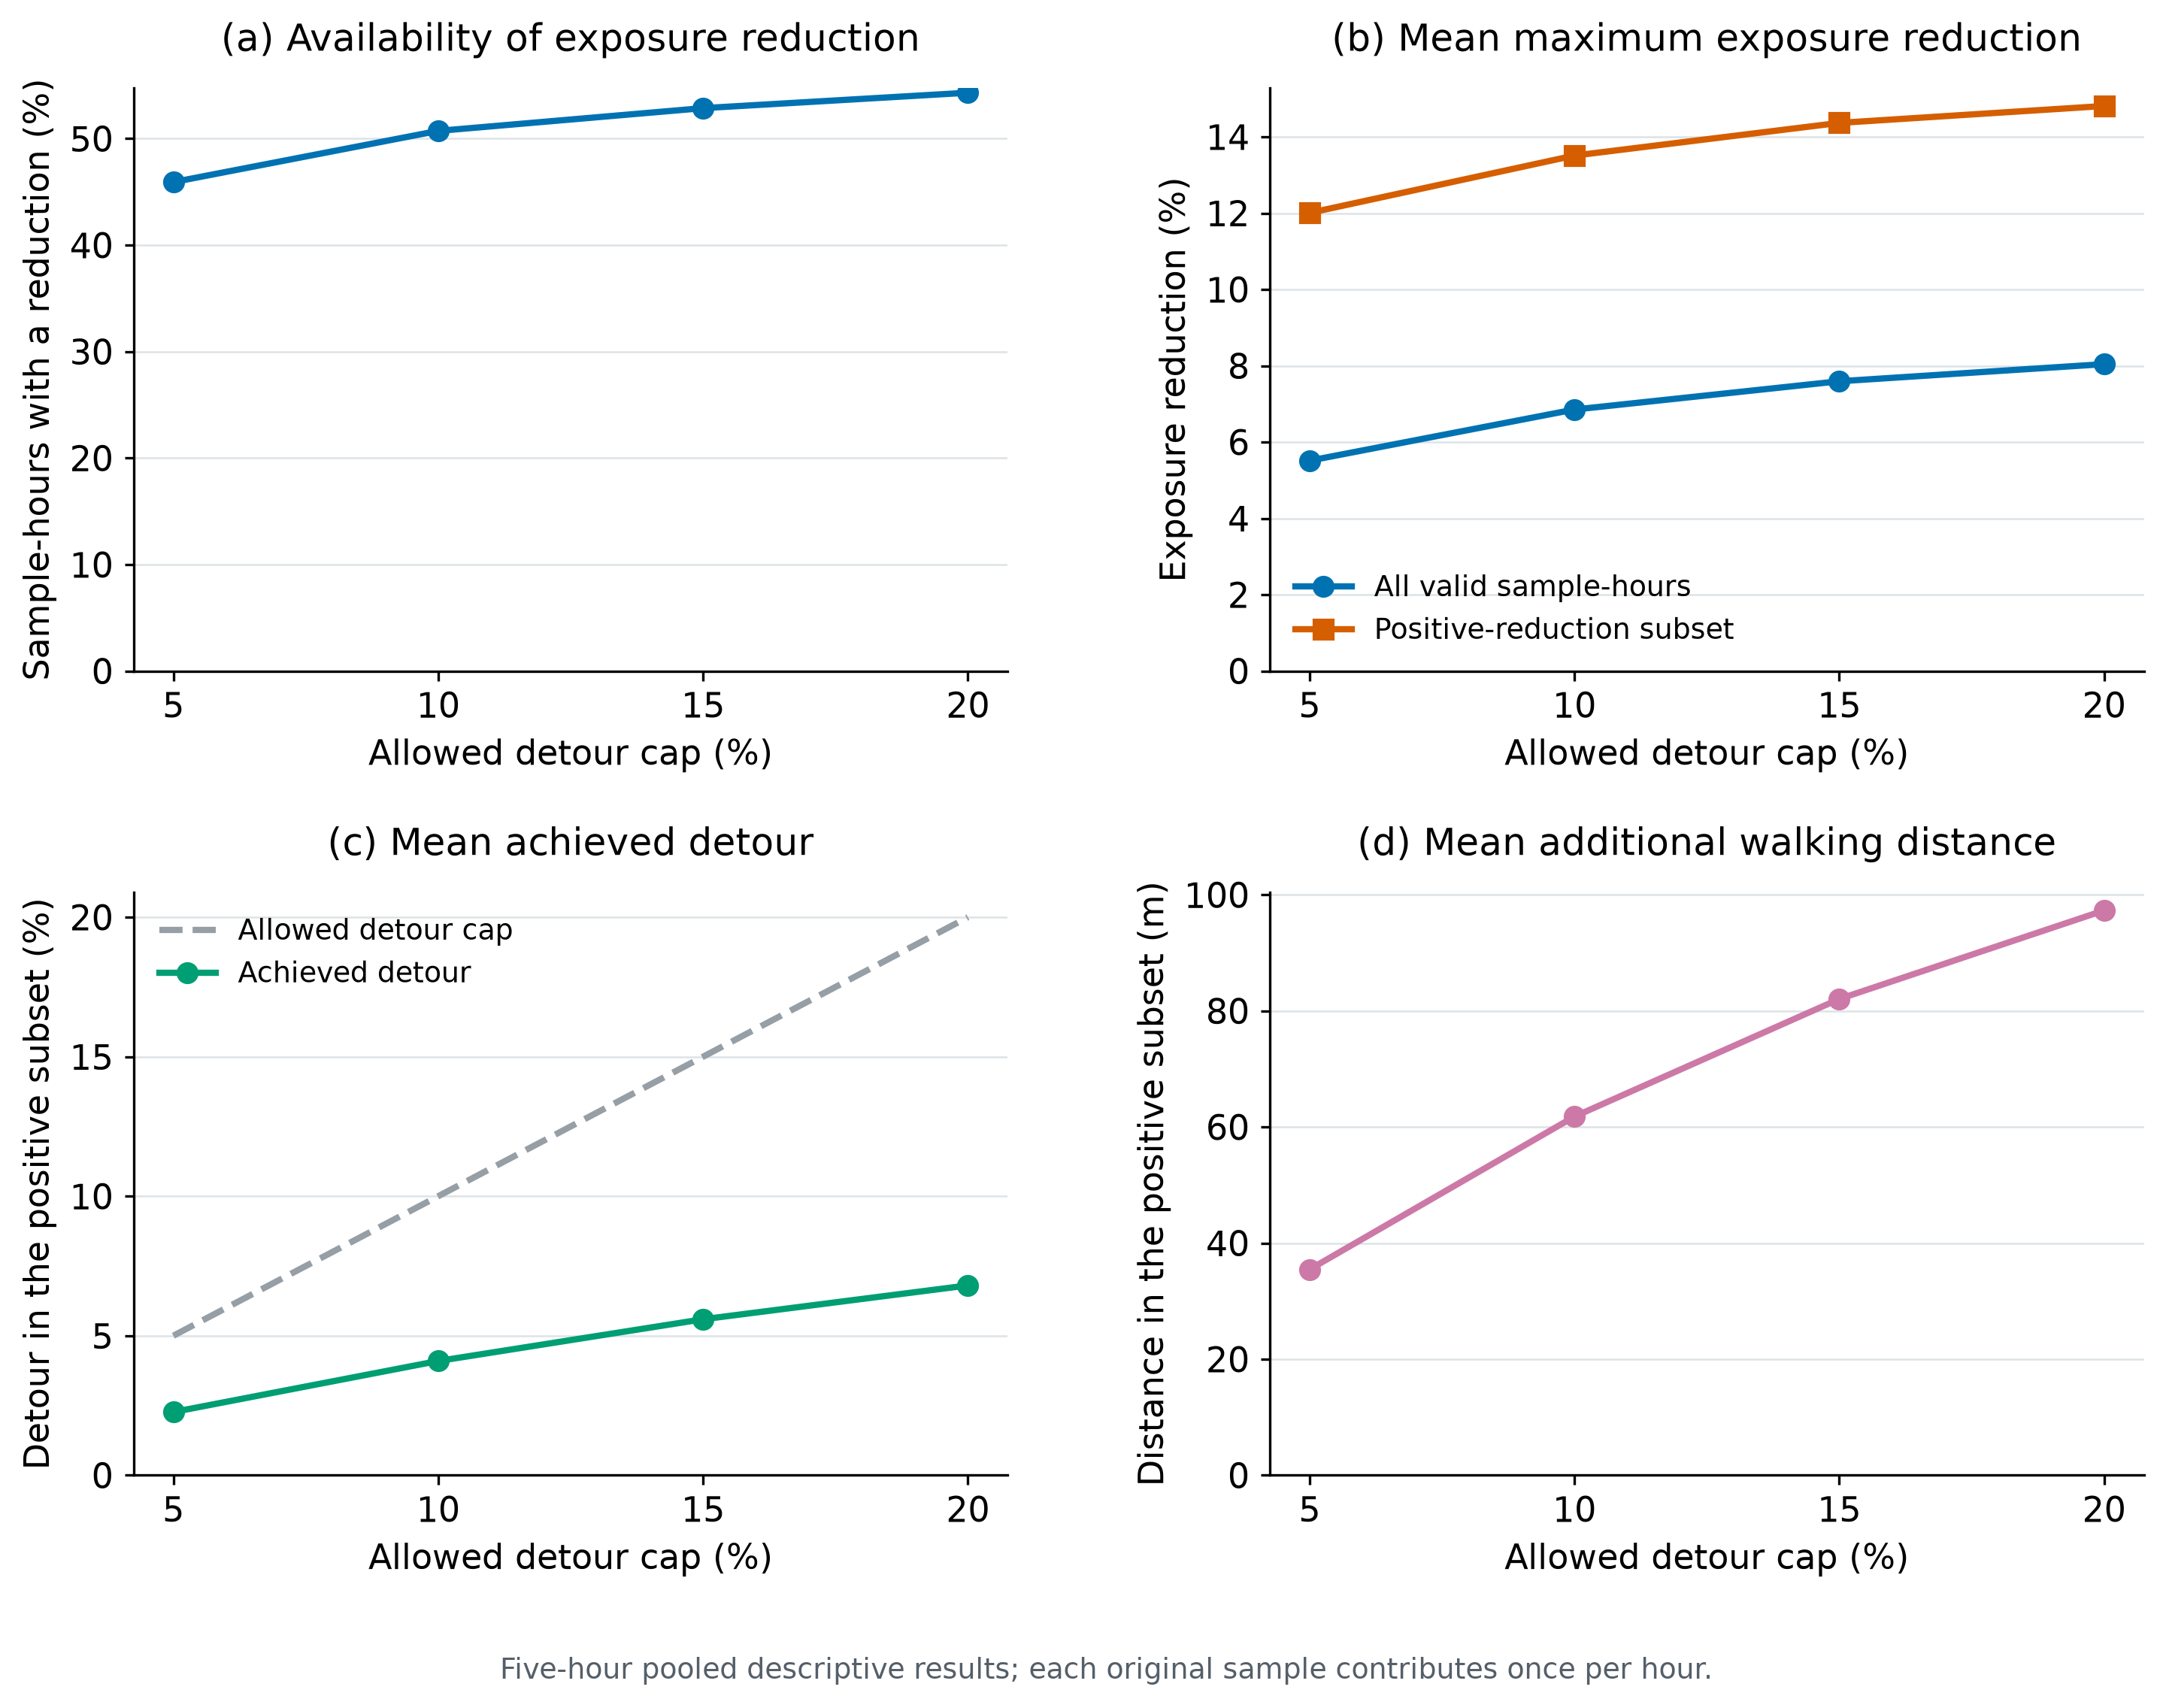

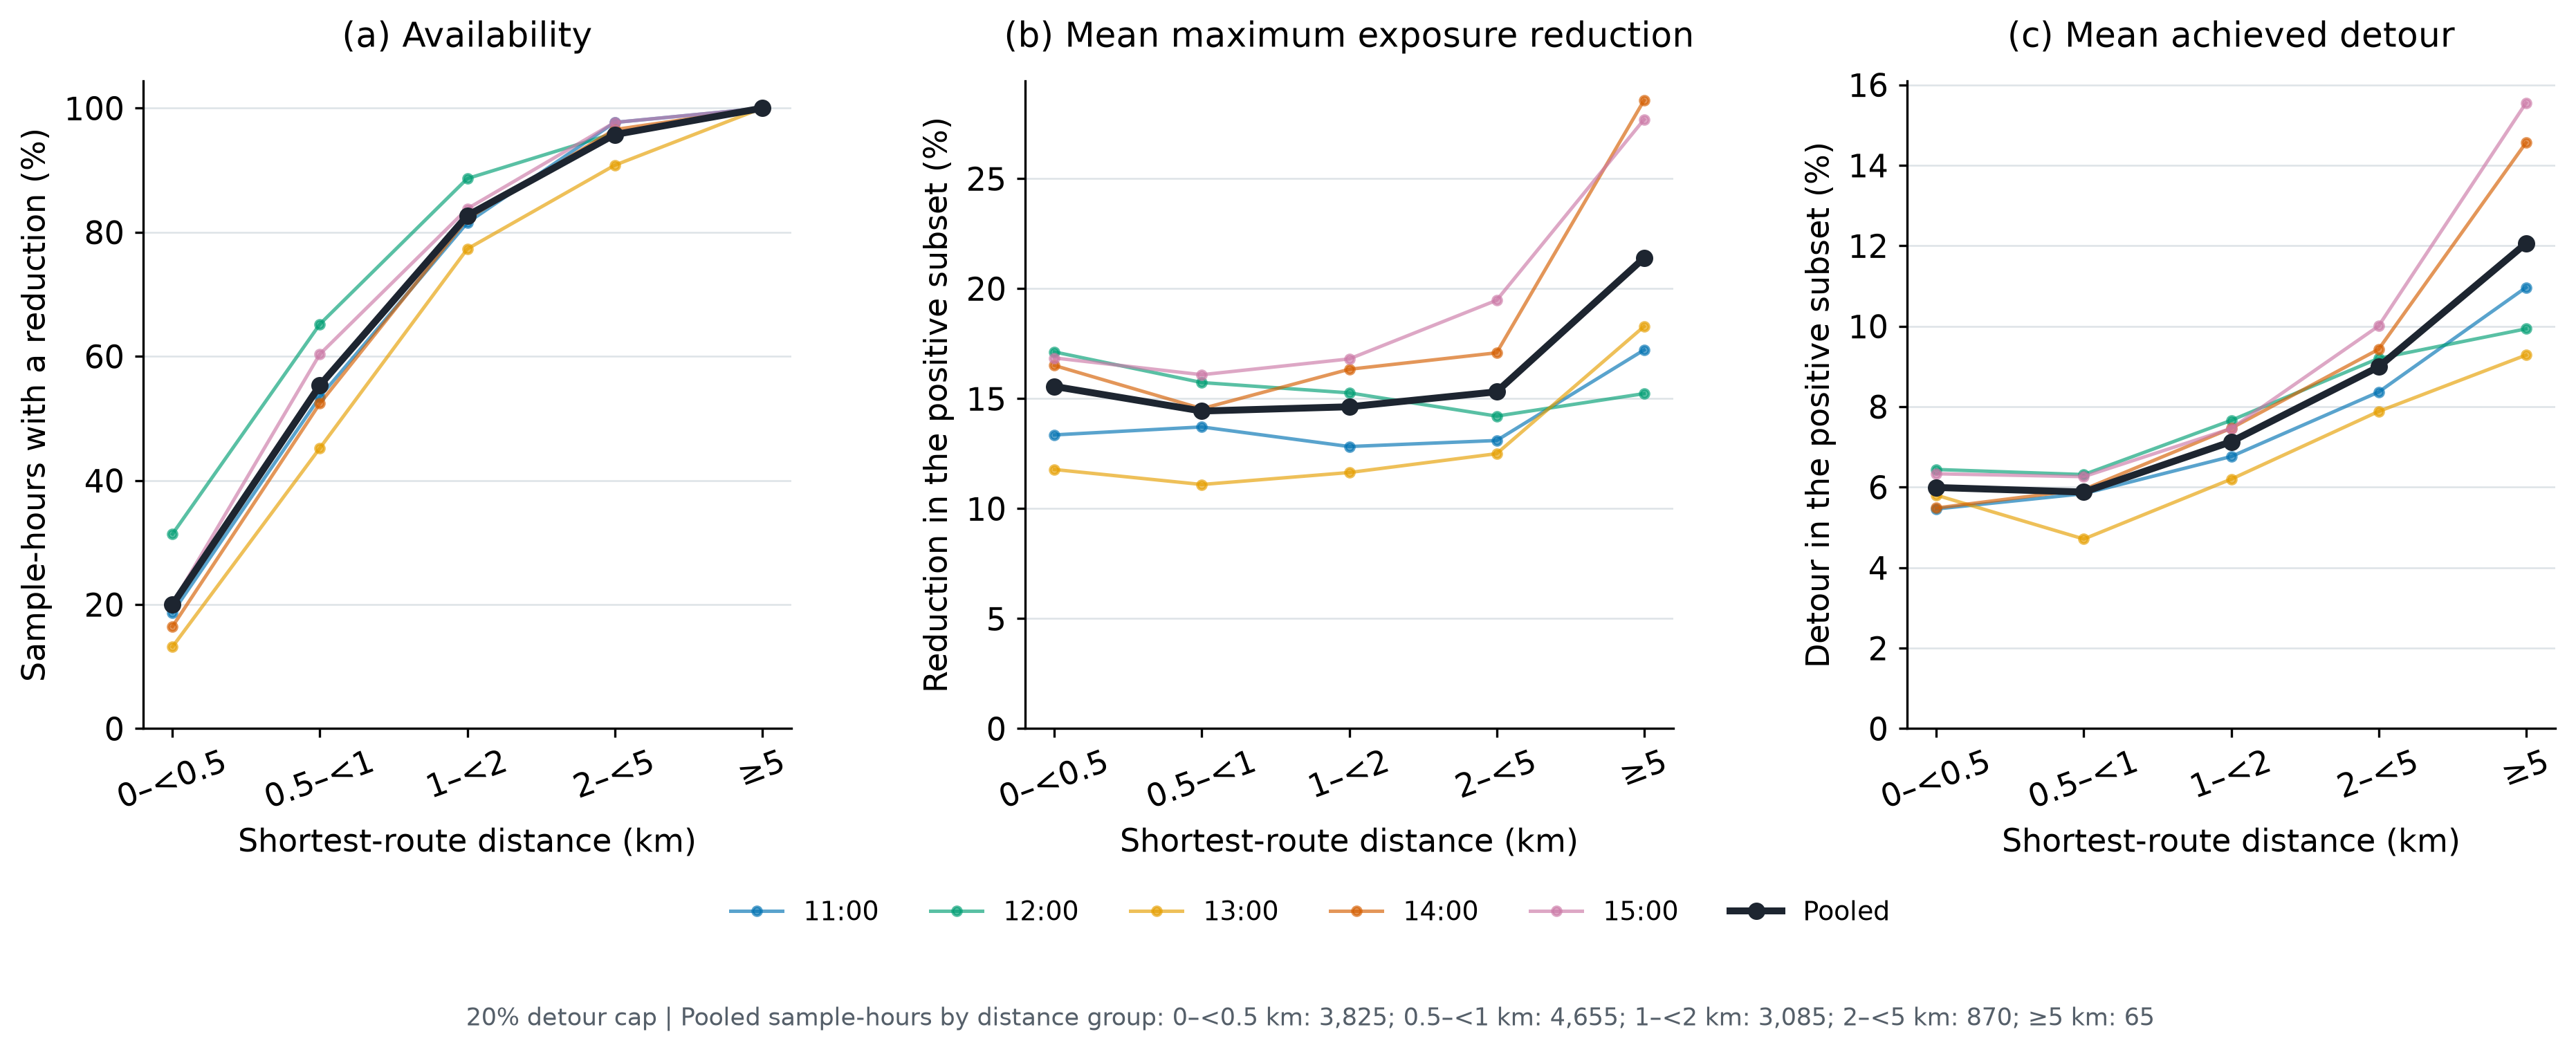

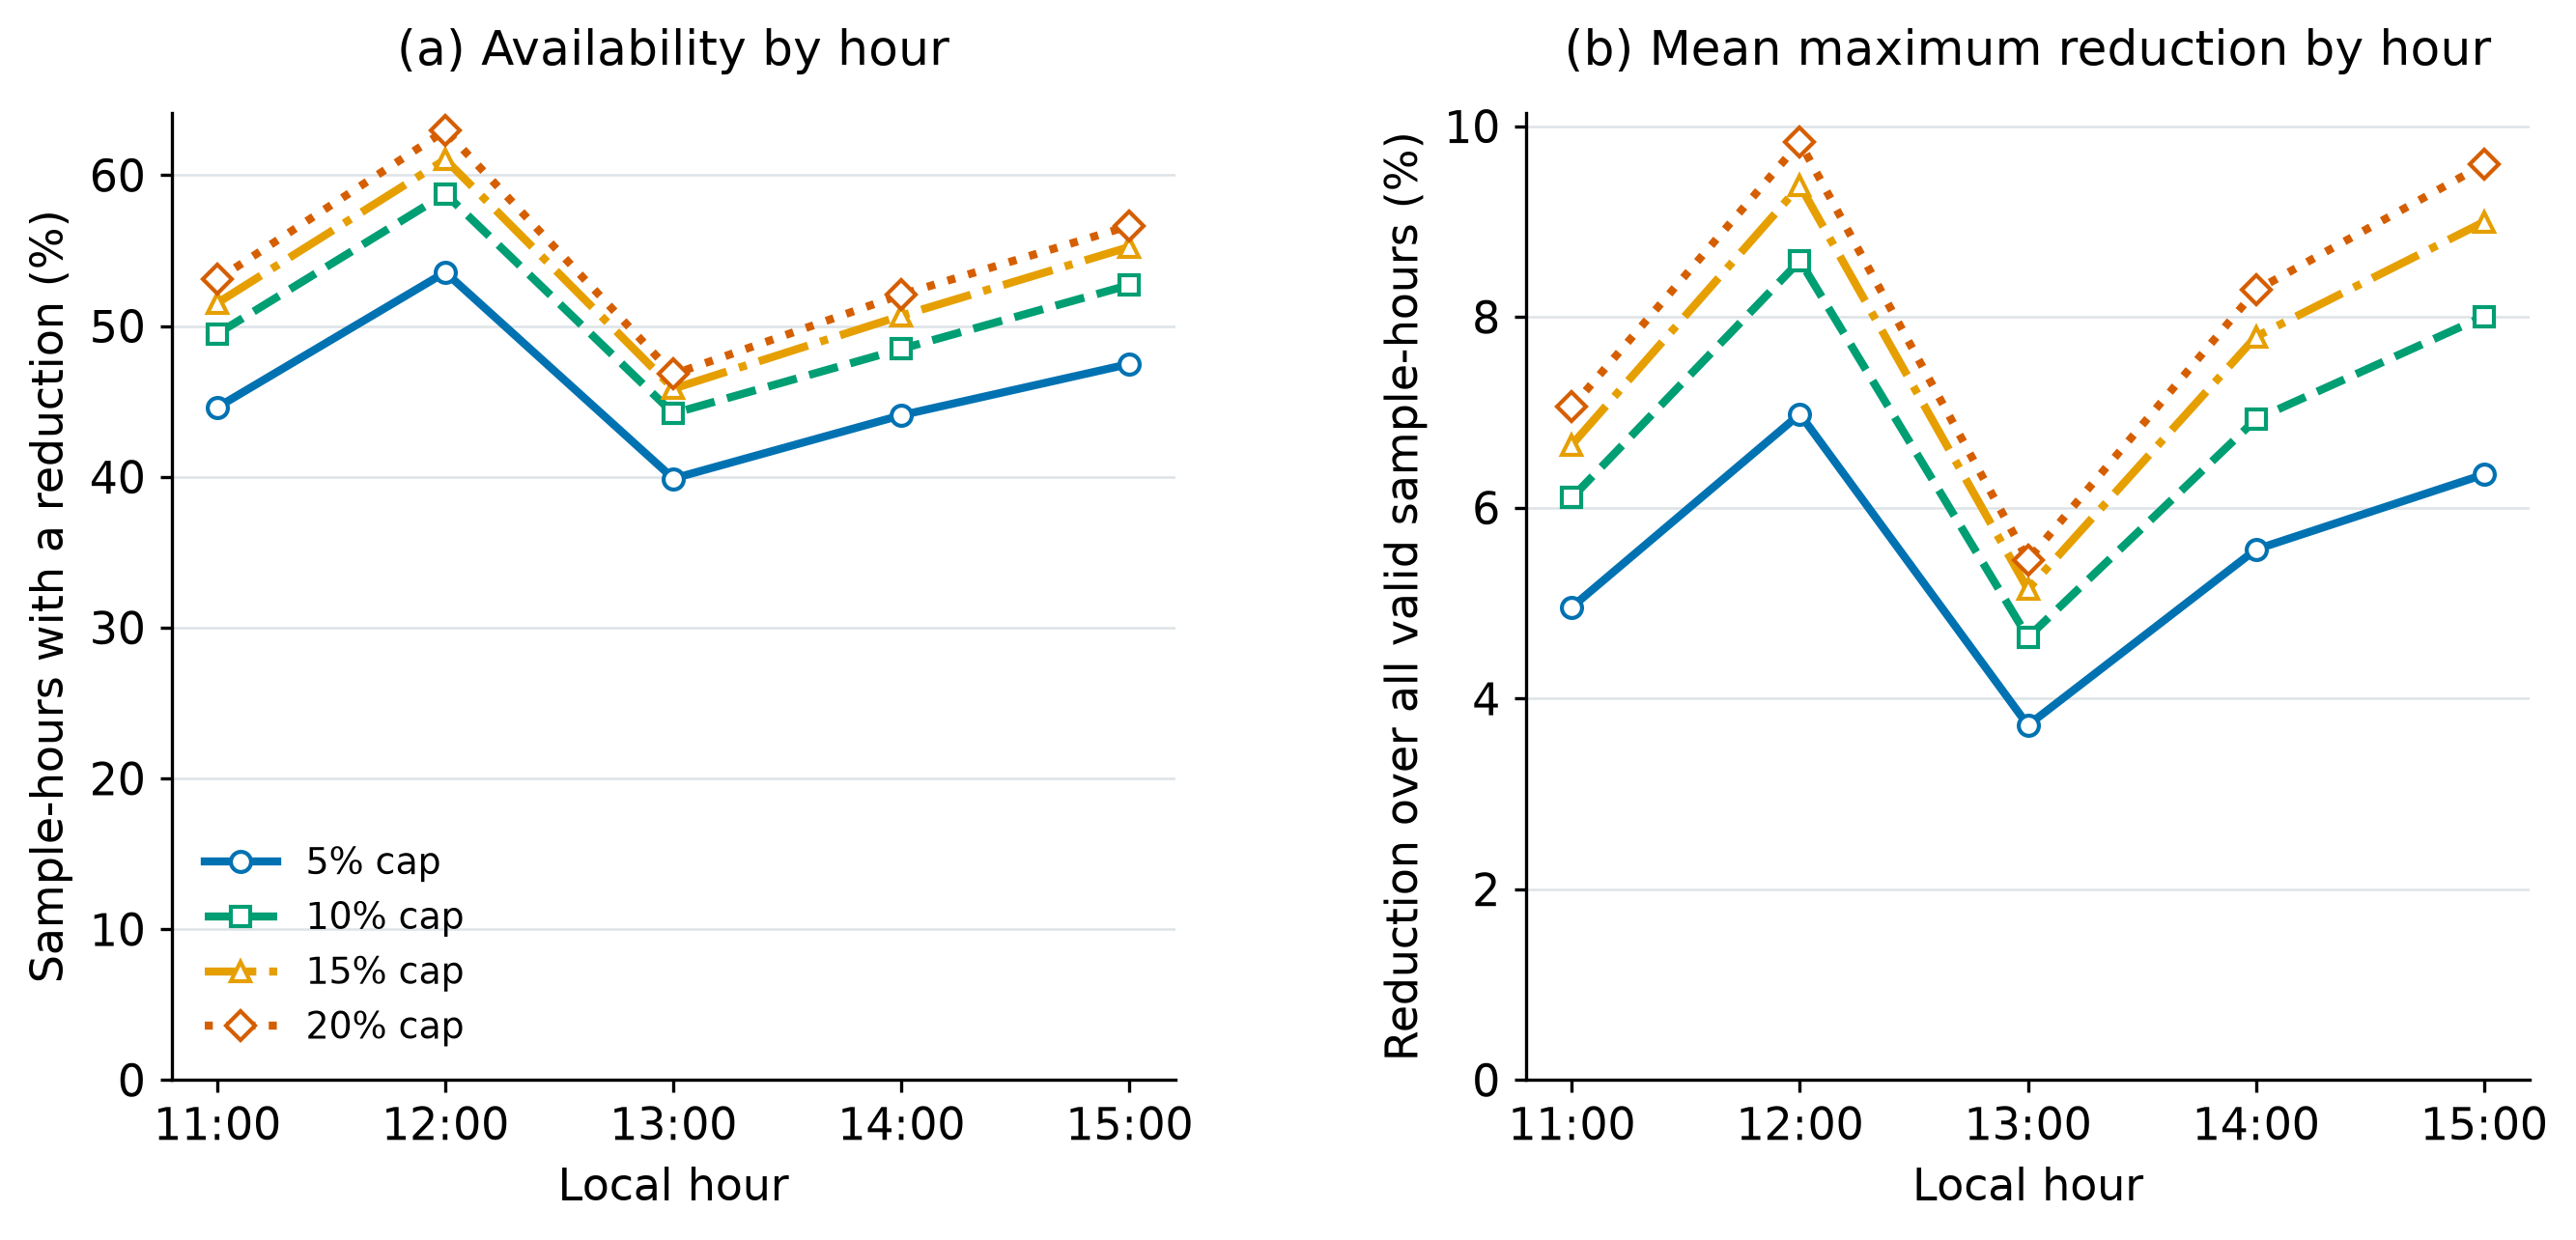

In [11]:
from IPython.display import display, Image

result_dir = Path(OUTPUT_DIR)

with (result_dir / "manifest.json").open("r", encoding="utf-8") as f:
    run_manifest = json.load(f)

main_cap = int(run_manifest["main_detour_cap_percent"])

main_table = pd.read_csv(
    result_dir / "tables" / f"main_scenario_{main_cap}pct.csv"
)

display(
    main_table[
        [
            "hour_label",
            "sample_hours",
            "positive_count",
            "positive_share_pct",
            "mean_reduction_all_pct",
            "mean_reduction_positive_pct",
            "mean_achieved_detour_positive_pct",
            "mean_additional_distance_positive_m",
        ]
    ].round(2)
)

for name in (
    "rq2_detour_tradeoffs.png",
    f"rq2_distance_variation_{main_cap}pct.png",
    "rq2_hourly_budget_comparison.png",
):
    display(Image(filename=str(result_dir / "figures" / name), width=1100))